In [75]:
import huggingface_hub
from datasets import load_dataset
from transformers import AutoTokenizer
import tiktoken
import pandas as pd
import matplotlib.pyplot as plt
import re
import numpy as np

huggingface_hub.login()  # FLORES+ is gated, accept its terms on Hugging Face first

In [76]:
ds_eng = load_dataset("openlanguagedata/flores_plus", "eng_Latn", split="dev")
ds_urdu = load_dataset("openlanguagedata/flores_plus", "urd_Arab", split="dev")
ds_pbt = load_dataset("openlanguagedata/flores_plus", "pbt_Arab", split="dev")

# alignment check: sentence i must have the same id in all three languages
assert len(ds_eng) == len(ds_urdu) == len(ds_pbt) == 997
assert list(ds_eng["id"]) == list(ds_urdu["id"]) == list(ds_pbt["id"])
print("All", len(ds_eng), "ids match")

df_eng = list(ds_eng["text"])
df_urdu = list(ds_urdu["text"])
df_pbt = list(ds_pbt["text"])

languages = {"English": df_eng, "Urdu": df_urdu, "Pashto": df_pbt}

All 997 ids match


In [77]:
encoders = {"cl100k_base" : tiktoken.get_encoding("cl100k_base"),
"o200k_base" : tiktoken.get_encoding("o200k_base"),
"gpt2" : AutoTokenizer.from_pretrained("gpt2"),
"Qwen" : AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B"),
"multilingual" : AutoTokenizer.from_pretrained("bert-base-multilingual-cased"),
"xlm" : AutoTokenizer.from_pretrained("xlm-roberta-base")}

In [78]:
def get_tokens(tokenizer, text):
    if isinstance(tokenizer, tiktoken.Encoding):
        return tokenizer.encode(text)
    return tokenizer.encode(text, add_special_tokens=False)


def fertility(tokenizer, dataset):
    scores = []
    for text in dataset:
        scores.append(len(get_tokens(tokenizer, text)) / len(text.split()))
    return sum(scores) / len(scores)


def parity(tokenizer, dataset, english):
    scores = []
    for text, eng_text in zip(dataset, english):
        scores.append(len(get_tokens(tokenizer, text)) / len(get_tokens(tokenizer, eng_text)))
    return sum(scores) / len(scores)


def ratios(tokenizer, dataset, english):
    scores = []
    for text, eng_text in zip(dataset, english):
        scores.append(len(get_tokens(tokenizer, text)) / len(get_tokens(tokenizer, eng_text)))
    return np.array(scores)

In [79]:
fertility_results = {}
parity_results = {}

for name, tokenizer in encoders.items():
    fertility_results[name] = {}
    parity_results[name] = {}
    for lang, data in languages.items():
        fertility_results[name][lang] = fertility(tokenizer, data)
        parity_results[name][lang] = parity(tokenizer, data, df_eng)

fertility_df = pd.DataFrame(fertility_results).T
parity_df = pd.DataFrame(parity_results).T

fertility_df.round(2)

print(parity_df.round(2))

              English  Urdu  Pashto
cl100k_base       1.0  4.46    3.90
o200k_base        1.0  1.68    1.78
gpt2              1.0  6.35    5.49
Qwen              1.0  3.24    2.93
multilingual      1.0  1.73    1.68
xlm               1.0  1.26    1.42


In [80]:
# bootstrap: resample the 997 sentences with replacement, 2000 times
rng = np.random.default_rng(42)
n_boot = 2000

rows = {}
for name, tokenizer in encoders.items():
    urdu = ratios(tokenizer, df_urdu, df_eng)
    pbt = ratios(tokenizer, df_pbt, df_eng)

    # same sentence ids for both languages in every resample (paired)
    idx = rng.integers(0, len(urdu), size=(n_boot, len(urdu)))
    urdu_means = urdu[idx].mean(axis=1)
    pbt_means = pbt[idx].mean(axis=1)
    gaps = urdu_means - pbt_means

    rows[name] = {
        "Urdu": urdu.mean(),
        "Urdu_low": np.percentile(urdu_means, 2.5),
        "Urdu_high": np.percentile(urdu_means, 97.5),
        "Pashto": pbt.mean(),
        "Pashto_low": np.percentile(pbt_means, 2.5),
        "Pashto_high": np.percentile(pbt_means, 97.5),
        "gap": urdu.mean() - pbt.mean(),
        "gap_low": np.percentile(gaps, 2.5),
        "gap_high": np.percentile(gaps, 97.5),
    }

boot_df = pd.DataFrame(rows).T
boot_df["gap_holds"] = (boot_df["gap_low"] > 0) | (boot_df["gap_high"] < 0)
boot_df.round(3)

,Urdu,Urdu_low,Urdu_high,Pashto,Pashto_low,Pashto_high,gap,gap_low,gap_high,gap_holds
cl100k_base,4.459,4.405,4.510,3.896,3.854,3.942,0.562,0.513,0.609,True
o200k_base,1.684,1.667,1.702,1.779,1.761,1.798,-0.095,-0.113,-0.076,True
gpt2,6.352,6.279,6.425,5.485,5.423,5.550,0.867,0.806,0.929,True
Qwen,3.236,3.197,3.273,2.932,2.898,2.966,0.304,0.270,0.338,True
multilingual,1.727,1.709,1.746,1.676,1.657,1.697,0.051,0.029,0.071,True
xlm,1.256,1.243,1.269,1.419,1.404,1.435,-0.163,-0.179,-0.146,True


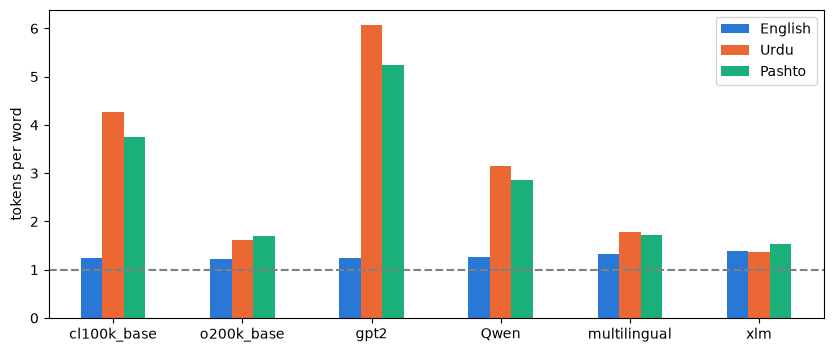

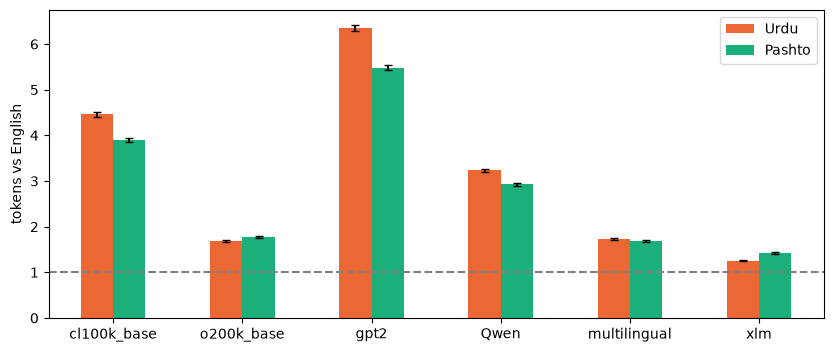

In [81]:
colors = ["#2a78d6", "#eb6834", "#1baf7a"]

fertility_df.plot.bar(figsize=(10, 4), rot=0, color=colors, ylabel="tokens per word")
plt.axhline(1, color="gray", linestyle="--")
plt.show()

# parity with 95% bootstrap intervals
errors = {}
for lang in ["Urdu", "Pashto"]:
    errors[lang] = np.array([boot_df[lang] - boot_df[lang + "_low"],
                             boot_df[lang + "_high"] - boot_df[lang]], dtype=float)

boot_df[["Urdu", "Pashto"]].astype(float).plot.bar(figsize=(10, 4), rot=0, color=colors[1:],
                                                   yerr=errors, capsize=3, ylabel="tokens vs English")
plt.axhline(1, color="gray", linestyle="--")
plt.show()

In [82]:
for lang in ["Urdu", "Pashto"]:
    best = parity_df[lang].idxmin()
    worst = parity_df[lang].idxmax()
    print(f"{lang}: best {best} ({parity_df[lang].min():.2f}x English), worst {worst} ({parity_df[lang].max():.2f}x English)")

Urdu: best xlm (1.26x English), worst gpt2 (6.35x English)
Pashto: best xlm (1.42x English), worst gpt2 (5.49x English)


In [83]:
i = 0  # sentence number to inspect

for lang, data in languages.items():
    print(lang, ":", data[i])
    for name, tokenizer in encoders.items():
        tokens = get_tokens(tokenizer, data[i])
        pieces = [tokenizer.decode([t]) for t in tokens]
        print(f"  {name:<13} {len(tokens):>3} | {' | '.join(pieces)}")
    print()

English : On Monday, scientists from the Stanford University School of Medicine announced the invention of a new diagnostic tool that can sort cells by type: a tiny printable chip that can be manufactured using standard inkjet printers for possibly about one U.S. cent each.
  cl100k_base    49 | On |  Monday | , |  scientists |  from |  the |  Stanford |  University |  School |  of |  Medicine |  announced |  the |  invention |  of |  a |  new |  diagnostic |  tool |  that |  can |  sort |  cells |  by |  type | : |  a |  tiny |  printable |  chip |  that |  can |  be |  manufactured |  using |  standard |  ink | jet |  printers |  for |  possibly |  about |  one |  U | .S | . |  cent |  each | .
  o200k_base     49 | On |  Monday | , |  scientists |  from |  the |  Stanford |  University |  School |  of |  Medicine |  announced |  the |  invention |  of |  a |  new |  diagnostic |  tool |  that |  can |  sort |  cells |  by |  type | : |  a |  tiny |  printable |  chip |  that |  can 

In [84]:
mbert = encoders["multilingual"]
for lang, data in languages.items():
    tokens = [t for text in data for t in mbert.tokenize(text)]
    print(f"mBERT [UNK] rate in {lang}: {tokens.count('[UNK]') / len(tokens):.2%}")

mBERT [UNK] rate in English: 0.14%
mBERT [UNK] rate in Urdu: 0.13%
mBERT [UNK] rate in Pashto: 16.68%


In [85]:
for lang, sentences in languages.items():
    english_letters = 0
    total_chars = 0
    english_words = 0
    for text in sentences:
        english_letters += len(re.findall(r"[a-zA-Z]", text))
        total_chars += len(text)
        for word in text.split():
            if re.search(r"[a-zA-Z]", word):
                english_words += 1
    print(lang, "| letters:", english_letters,
          "| % of chars:", round(100 * english_letters / total_chars, 2),
          "| words with English letters:", english_words)

English | letters: 101352 | % of chars: 80.96 | words with English letters: 20674
Urdu | letters: 364 | % of chars: 0.29 | words with English letters: 86
Pashto | letters: 3850 | % of chars: 3.15 | words with English letters: 637


In [86]:
def has_english(text):
    return re.search(r"[a-zA-Z]", text) is not None

keep = []
for i in range(len(df_eng)):
    if not has_english(df_urdu[i]) and not has_english(df_pbt[i]):
        keep.append(i)

print(len(keep), "of", len(df_eng), "sentences kept")

eng_kept = []
urdu_kept = []
pbt_kept = []
for i in keep:
    eng_kept.append(df_eng[i])
    urdu_kept.append(df_urdu[i])
    pbt_kept.append(df_pbt[i])

enc = encoders["cl100k_base"]

print("All sentences   -> Urdu:", round(parity(enc, df_urdu, df_eng), 2),
      "| Pashto:", round(parity(enc, df_pbt, df_eng), 2))
print("No-English only -> Urdu:", round(parity(enc, urdu_kept, eng_kept), 2),
      "| Pashto:", round(parity(enc, pbt_kept, eng_kept), 2))
print("Pashto / Urdu on same sentences:", round(parity(enc, pbt_kept, urdu_kept), 2))

726 of 997 sentences kept
All sentences   -> Urdu: 4.46 | Pashto: 3.9
No-English only -> Urdu: 4.57 | Pashto: 3.95
Pashto / Urdu on same sentences: 0.88


In [87]:
swap = {
    "\u06C1": "\u0647",  # ہ -> ه
    "\u06BE": "\u0647",  # ھ -> ه
    "\u06D2": "\u06CC",  # ے -> ی
    "\u06BA": "\u0646",  # ں -> ن
}

urdu_swapped = []
changed = 0
for text in urdu_kept:
    for old, new in swap.items():
        changed += text.count(old)
        text = text.replace(old, new)
    urdu_swapped.append(text)

print("Letters replaced:", changed)
print("Example:", urdu_kept[0])
print("Swapped:", urdu_swapped[0])

for name in ["cl100k_base", "o200k_base"]:
    enc = encoders[name]
    print("\n" + name)
    print("  Urdu original:", round(parity(enc, urdu_kept, eng_kept), 2))
    print("  Urdu swapped: ", round(parity(enc, urdu_swapped, eng_kept), 2))
    print("  Pashto:       ", round(parity(enc, pbt_kept, eng_kept), 2))

Letters replaced: 10071
Example: مقامی میڈیا نے بتایا کہ ہوائی اڈے کی ایک آگ بھجانے والی گاڑی کاروائی کرتے وقت الٹ گئی۔
Swapped: مقامی میڈیا نی بتایا که هوائی اڈی کی ایک آگ بهجانی والی گاڑی کاروائی کرتی وقت الٹ گئی۔

cl100k_base
  Urdu original: 4.57
  Urdu swapped:  3.83
  Pashto:        3.95

o200k_base
  Urdu original: 1.69
  Urdu swapped:  1.82
  Pashto:        1.76
